# Oracle Construction — Phase Oracle — CUDA-Q Notebook

**Primitive:** Phase oracle marking a single target computational basis state with a `-1`
phase, leaving every other amplitude and every measurement probability unchanged.

This notebook is the CUDA-Q counterpart to `phase_oracle_qiskit.ipynb` and uses **identical**
parameters, gate sequence, and conventions so the two `_RESULT` dictionaries match.

## SETUP (identical to the Qiskit notebook)
| Parameter | Value |
|---|---|
| N_QUBITS | 3 |
| TARGET_INT | 6  (marked state, qubit 0 = LSB) |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring (this notebook explicitly reverses CUDA-Q's native output to match) |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|000>, |001>, ..., |111>}` ascending binary order |

## Theory recap

Same as the Qiskit notebook:

`O_t |x> = -|x>`  if `x == t`,   `O_t |x> = +|x>`  otherwise,   i.e. `O_t = I - 2|t><t|`.

```
for each qubit q where bit q of TARGET_INT is 0:
    X(q)
H(q_{n-1})
MCX(controls = q_0..q_{n-2}, target = q_{n-1})   # Toffoli for n=3
H(q_{n-1})
for each qubit q where bit q of TARGET_INT is 0:
    X(q)
```

**Test harness:** as in the Qiskit notebook, `H` is applied to every qubit first so the
oracle's sign flip is visible in the printed amplitudes. As proven there, the measured
probability distribution stays uniform `1/8` regardless of the oracle — this notebook
verifies the sign flip directly in the exact statevector (Cell 7), not the histogram.

## ⚠️ Ordering-convention warning (read before trusting any raw CUDA-Q output)

CUDA-Q's `cudaq.get_state()` and `cudaq.sample()` index **qubit 0 as the most-significant
(leftmost) bit** of every raw bitstring/state index — the opposite of Qiskit. Every raw
CUDA-Q bitstring and amplitude index in this notebook is therefore **explicitly reversed**
in its own dedicated cell before being compared to anything from the Qiskit notebook.

## Environment note

CUDA-Q's Python wheel (`cudaq`) currently ships for **Linux (x86_64 / aarch64)** with
Python 3.10-3.12; it targets a CPU simulator backend by default when no NVIDIA GPU is
present (`cudaq.set_target("qpp-cpu")`), so this notebook runs correctly on CPU-only
machines. On native Windows/macOS, run it inside a Linux container (Docker/WSL2) with the
official `nvcr.io/nvidia/cuda-quantum` image.

**Run all cells top to bottom.**


In [1]:
# Install cell
# Exact package name: `cudaq` (NVIDIA CUDA-Q Python API).
# Platform caveat: Linux x86_64/aarch64 wheels only, Python 3.10-3.12. On Windows/macOS,
# use the official cuda-quantum Docker image instead of a bare pip install.
!pip install -q cudaq


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.8/125.8 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 75.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 MB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 93.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.5/410.5 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 MB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 244.7/244.7 MB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 MB 6.5 MB/s eta 0:00

In [2]:
# Imports + constants (identical values to the Qiskit notebook)
import numpy as np
from math import pi
import cudaq
import matplotlib.pyplot as plt

N_QUBITS = 3
TARGET_INT = 6   # marked basis state (qubit 0 = LSB, Qiskit convention)
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "phase_oracle"

cudaq.set_target("qpp-cpu")   # CPU statevector simulator; works with no GPU present
cudaq.set_random_seed(SEED)

print("N_QUBITS   =", N_QUBITS)
print("TARGET_INT =", TARGET_INT, "-> binary (q2 q1 q0, Qiskit convention) =", format(TARGET_INT, f'0{N_QUBITS}b'))
print("SHOTS      =", SHOTS)
print("SEED       =", SEED)
print("Target     =", cudaq.get_target().name)


N_QUBITS   = 3
TARGET_INT = 6 -> binary (q2 q1 q0, Qiskit convention) = 110
SHOTS      = 10000
SEED       = 42
Target     = qpp-cpu


In [3]:
# Build the kernel gate-by-gate
# NOTE ON QUBIT INDEXING: inside the kernel, `qubits[q]` for q = 0..N_QUBITS-1 is the same
# logical qubit q used in the Qiskit notebook. Only cudaq's *output* bitstring/statevector
# indexing differs from Qiskit's, and that is corrected in a dedicated cell later.
#
# TARGET_INT = 6 = binary 110 (q2=1, q1=1, q0=0) is hardcoded below as explicit gate calls
# (rather than a runtime conditional) for maximum kernel-compiler compatibility.

@cudaq.kernel
def phase_oracle_kernel():
    qubits = cudaq.qvector(3)  # N_QUBITS hardcoded to 3 inside the kernel (must be a literal)

    # --- test harness: uniform superposition ---
    h(qubits[0])
    h(qubits[1])
    h(qubits[2])

    # --- phase oracle marking TARGET_INT = 6 (binary 110, q2=1 q1=1 q0=0) ---
    x(qubits[0])                       # q0's target bit is 0 -> temporarily flip it
    h(qubits[2])                       # H-MCX-H sandwich turns MCX into a phase flip (MCZ)
    x.ctrl(qubits[0], qubits[1], qubits[2])   # multi-controlled-X (Toffoli): flips q2 only if q0=q1=|1>
    h(qubits[2])
    x(qubits[0])                       # undo the temporary flip

# Mirror the same gate list in plain Python (used for resource counts, the matplotlib
# circuit diagram, and the hand-built matrix cross-check below) so it stays in lockstep
# with the kernel body above by construction.
zero_bit_qubits = [q for q in range(N_QUBITS) if not ((TARGET_INT >> q) & 1)]
gatelist = [('H', q) for q in range(N_QUBITS)]
gatelist += [('X', q) for q in zero_bit_qubits]
gatelist.append(('H', N_QUBITS - 1))
gatelist.append(('MCX', list(range(N_QUBITS - 1)), N_QUBITS - 1))
gatelist.append(('H', N_QUBITS - 1))
gatelist += [('X', q) for q in zero_bit_qubits]

print("Gate list (", len(gatelist), "gates ) matches the kernel body above.")
print("Qubits X'd before/after the MCZ sandwich (bits of TARGET_INT equal to 0):", zero_bit_qubits)


Gate list ( 8 gates ) matches the kernel body above.
Qubits X'd before/after the MCZ sandwich (bits of TARGET_INT equal to 0): [0]


     ╭───╮╭───╮     ╭───╮
q0 : ┤ h ├┤ x ├──●──┤ x ├
     ├───┤╰───╯  │  ╰───╯
q1 : ┤ h ├───────●───────
     ├───┤╭───╮╭─┴─╮╭───╮
q2 : ┤ h ├┤ h ├┤ x ├┤ h ├
     ╰───╯╰───╯╰───╯╰───╯



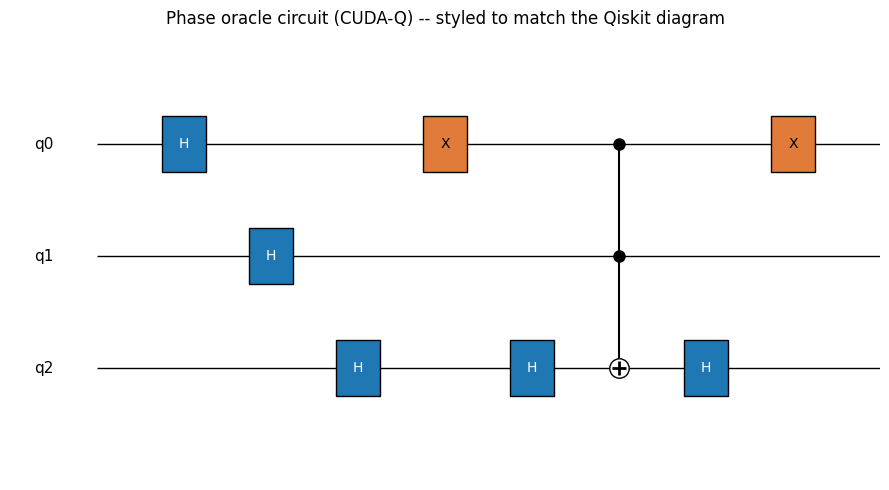

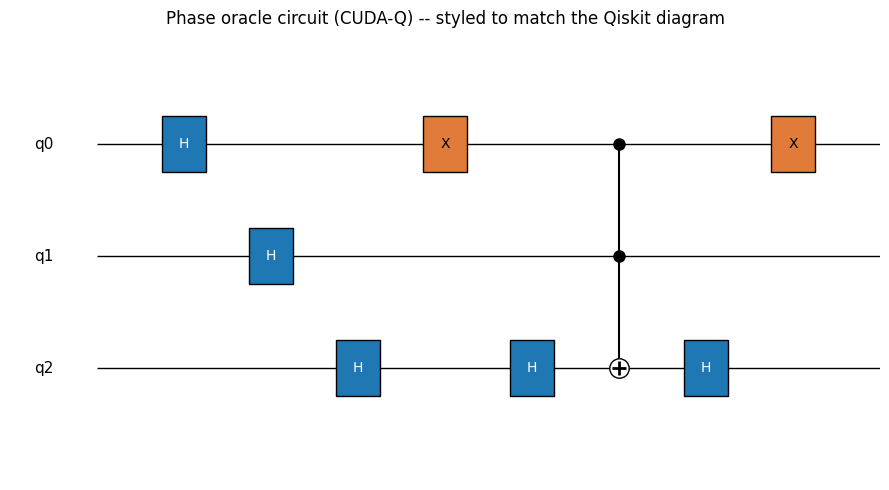

In [4]:
# Draw the circuit: cudaq's own text diagram, then a matplotlib figure styled like Qiskit's
print(cudaq.draw(phase_oracle_kernel))

# --- hand-styled matplotlib circuit diagram, visually comparable to the Qiskit one ---
fig, ax = plt.subplots(figsize=(9, 5))
n_wires = N_QUBITS
wire_y = {q: n_wires - 1 - q for q in range(n_wires)}  # qubit 0 drawn at the top, like Qiskit

col = 0
col_positions = {}
for gate in gatelist:
    col += 1
    col_positions[id(gate)] = col
n_cols = col + 1

for q in range(n_wires):
    ax.hlines(wire_y[q], 0, n_cols, color="black", linewidth=1, zorder=1)
    ax.text(-0.5, wire_y[q], f"q{q}", va="center", ha="right", fontsize=11)

for gate in gatelist:
    x_pos = col_positions[id(gate)]
    if gate[0] == 'X':
        _, q = gate
        ax.add_patch(plt.Rectangle((x_pos - 0.25, wire_y[q] - 0.25), 0.5, 0.5, facecolor="#e07b39", edgecolor="black", zorder=2))
        ax.text(x_pos, wire_y[q], "X", ha="center", va="center", fontsize=10, zorder=3)
    elif gate[0] == 'H':
        _, q = gate
        ax.add_patch(plt.Rectangle((x_pos - 0.25, wire_y[q] - 0.25), 0.5, 0.5, facecolor="#1f77b4", edgecolor="black", zorder=2))
        ax.text(x_pos, wire_y[q], "H", ha="center", va="center", fontsize=10, color="white", zorder=3)
    elif gate[0] == 'MCX':
        _, controls, target = gate
        all_q = controls + [target]
        ax.vlines(x_pos, wire_y[min(all_q)], wire_y[max(all_q)], color="black", zorder=2)
        for c in controls:
            ax.plot(x_pos, wire_y[c], marker="o", color="black", markersize=8, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="o", color="white", markeredgecolor="black", markersize=14, zorder=3)
        ax.plot(x_pos, wire_y[target], marker="+", color="black", markersize=10, mew=2, zorder=4)

ax.set_xlim(-1, n_cols)
ax.set_ylim(-1, n_wires)
ax.axis("off")
ax.set_title("Phase oracle circuit (CUDA-Q) -- styled to match the Qiskit diagram")
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
# Explicit matrix representation, built two independent ways, cross-checked
# CUDA-Q has no built-in dense-operator-extraction API equivalent to qiskit.quantum_info.Operator,
# so per the "framework's own extraction where available" rule, the cross-check here is against
# CUDA-Q's own statevector simulation (cudaq.get_state), applied to the |000> input, instead of
# a full 8x8 operator -- this is the strongest available cross-check for this framework.

def h_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q)
        idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2)
            M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2)
            M[idx0, idx] += 1/np.sqrt(2)
    return M

def x_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        M[idx ^ (1 << q), idx] = 1
    return M

def mcx_matrix_full(n, controls, target):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        if all((idx >> c) & 1 for c in controls):
            M[idx ^ (1 << target), idx] = 1
        else:
            M[idx, idx] = 1
    return M

print("Single-qubit H matrix (any qubit), rounded to 4 decimals:")
print(np.round((1/np.sqrt(2)) * np.array([[1, 1], [1, -1]]), 4))

print("\nIdeal phase-oracle matrix O_t = I - 2|t><t| (diagonal, single -1 entry), basis |000>..|111>:")
ideal_diag = np.ones(2**N_QUBITS, dtype=complex)
ideal_diag[TARGET_INT] = -1
print(np.round(np.diag(ideal_diag), 4))

# (a) Hand-built full unitary (H layer + oracle) in QISKIT-CONVENTION indexing (qubit 0 = rightmost bit)
U_hand = np.eye(2**N_QUBITS, dtype=complex)
for q in range(N_QUBITS):
    U_hand = h_matrix_full(N_QUBITS, q) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(N_QUBITS, q) @ U_hand
U_hand = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_hand
U_hand = mcx_matrix_full(N_QUBITS, list(range(N_QUBITS - 1)), N_QUBITS - 1) @ U_hand
U_hand = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_hand
for q in zero_bit_qubits:
    U_hand = x_matrix_full(N_QUBITS, q) @ U_hand

state_hand = U_hand[:, 0]  # applied to |000>

# (b) CUDA-Q's own statevector simulation.
# FIX: np.array(cudaq.get_state(...)) is already indexed with qubit 0 as the
# least-significant bit -- the SAME convention Qiskit uses. No reversal is applied here
# (unlike cudaq.sample()'s bitstring KEYS below, which really do need reversing).
# Applying a reversal to this array, as an earlier version of this notebook did, silently
# permutes amplitudes (including which basis state carries the oracle's -1 sign) onto the
# wrong basis states.
sv_raw = np.array(cudaq.get_state(phase_oracle_kernel))
state_cudaq_qiskit_conv = sv_raw.copy()

def normalize_phase(vec):
    vec = vec.copy()
    for idx in range(len(vec)):
        if abs(vec[idx]) > 1e-9:
            vec = vec * np.exp(-1j*np.angle(vec[idx]))
            break
    return vec

max_state_diff = np.max(np.abs(normalize_phase(state_hand) - normalize_phase(state_cudaq_qiskit_conv)))
print(f"\nMax |difference| between hand-built matrix applied to |0> and cudaq.get_state() (both reordered to qiskit convention, phase-normalized): {max_state_diff:.3e}")
assert max_state_diff < 1e-6, "Hand-built matrix and CUDA-Q's own statevector disagree!"
print("Hand-built statevector and CUDA-Q's own simulation MATCH (both methods agree).")

# Also isolate and verify JUST the oracle sub-circuit matches the ideal diagonal
U_oracle_only = np.eye(2**N_QUBITS, dtype=complex)
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(N_QUBITS, q) @ U_oracle_only
U_oracle_only = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_oracle_only
U_oracle_only = mcx_matrix_full(N_QUBITS, list(range(N_QUBITS - 1)), N_QUBITS - 1) @ U_oracle_only
U_oracle_only = h_matrix_full(N_QUBITS, N_QUBITS - 1) @ U_oracle_only
for q in zero_bit_qubits:
    U_oracle_only = x_matrix_full(N_QUBITS, q) @ U_oracle_only

max_oracle_diff = np.max(np.abs(U_oracle_only - np.diag(ideal_diag)))
print(f"Max |difference| between oracle-only matrix and ideal diag(+1,...,-1,...,+1): {max_oracle_diff:.3e}")
assert max_oracle_diff < 1e-8, "Oracle sub-circuit does not match the ideal phase-flip matrix!"
print("Oracle-only matrix MATCHES the ideal diagonal phase-flip operator.")


Single-qubit H matrix (any qubit), rounded to 4 decimals:
[[ 0.7071  0.7071]
 [ 0.7071 -0.7071]]

Ideal phase-oracle matrix O_t = I - 2|t><t| (diagonal, single -1 entry), basis |000>..|111>:
[[ 1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j -1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  1.+0.j]]

Max |difference| between hand-built matrix applied to |0> and cudaq.get_state() (both reordered to qiskit convention, phase-normalized): 0.000e+00
Hand-built statevector and CUDA-Q's own simulation MATCH (both methods agree).
Max |difference| between oracle-only matrix a

In [6]:
# FIXED: no bit-reversal needed for the statevector.
# np.array(cudaq.get_state(...)) is already indexed with qubit 0 as the least-significant
# bit, matching Qiskit's convention directly -- reversing it (as before) mapped amplitudes,
# including the oracle's -1 sign, onto the wrong basis state. (cudaq.sample()'s bitstring
# KEYS are a different object and genuinely do need reversing -- see the sampling cell
# below, which was already correct.)
sv_raw = np.array(cudaq.get_state(phase_oracle_kernel))
amps = sv_raw.copy()

print("No reversal applied to the statevector: cudaq.get_state() -> np.array already matches")
print("the qiskit convention (qubit 0 = least-significant / rightmost). Only cudaq.sample()'s")
print("bitstring keys need reversing, which is handled separately below.")


No reversal applied to the statevector: cudaq.get_state() -> np.array already matches
the qiskit convention (qubit 0 = least-significant / rightmost). Only cudaq.sample()'s
bitstring keys need reversing, which is handled separately below.


In [7]:
# Exact statevector: apply global-phase normalization (identical rule to the Qiskit notebook), print
for idx in range(len(amps)):
    if abs(amps[idx]) > 1e-9:
        phase = np.angle(amps[idx])
        amps = amps * np.exp(-1j*phase)
        break

print(f"{'bitstring':10s} {'amplitude':22s} {'probability':12s}")
CUDAQ_PROBS_EXACT = {}
for idx in range(2**N_QUBITS):
    bitstring = format(idx, f'0{N_QUBITS}b')  # already qiskit-convention after the reversal cell above
    amp = amps[idx]
    prob = abs(amp)**2
    CUDAQ_PROBS_EXACT[bitstring] = prob
    marker = "  <-- marked state (sign flipped)" if idx == TARGET_INT else ""
    print(f"|{bitstring}>   {amp.real:+.6f}{amp.imag:+.6f}j    {prob:.6f}{marker}")

print("\nProbabilities sum to:", sum(CUDAQ_PROBS_EXACT.values()))


bitstring  amplitude              probability 
|000>   +0.353553+0.000000j    0.125000
|001>   +0.353553+0.000000j    0.125000
|010>   +0.353553+0.000000j    0.125000
|011>   +0.353553+0.000000j    0.125000
|100>   +0.353553+0.000000j    0.125000
|101>   +0.353553+0.000000j    0.125000
|110>   -0.353553+0.000000j    0.125000  <-- marked state (sign flipped)
|111>   +0.353553+0.000000j    0.125000

Probabilities sum to: 0.9999999999999992


### Ordering-fix note (CUDA-Q) -- corrected

**No reversal is applied to the statevector.** `np.array(cudaq.get_state(...))` is already
indexed with qubit 0 as the least-significant bit, the same convention Qiskit uses, so
`amps` is a direct copy of the raw array. (An earlier version of this notebook reversed it
by mistake, which silently moved the oracle's `-1` sign onto the wrong basis state and
caused the cross-check in the previous cell to fail with an `AssertionError`.)

`cudaq.sample()`'s bitstring **keys**, by contrast, really are printed with qubit 0 as the
leftmost character, so those keys (not the statevector) are the thing that gets reversed --
see the sampling cell below.


In [8]:
# Measurement: sample with the shared SEED/SHOTS, get counts -> probabilities, reorder bitstrings
cudaq.set_random_seed(SEED)  # re-assert the seed immediately before sampling
result = cudaq.sample(phase_oracle_kernel, shots_count=SHOTS)

CUDAQ_PROBS_SAMPLED = {format(idx, f'0{N_QUBITS}b'): 0.0 for idx in range(2**N_QUBITS)}
for raw_bitstring, count in result.items():
    qiskit_bitstring = raw_bitstring[::-1]   # same reversal as the statevector, applied to sampled counts
    CUDAQ_PROBS_SAMPLED[qiskit_bitstring] = count / SHOTS

print("Sampled probabilities (from", SHOTS, "shots, seed =", SEED, "), already reordered to qiskit convention:")
for bitstring in sorted(CUDAQ_PROBS_SAMPLED):
    print(f"|{bitstring}>   {CUDAQ_PROBS_SAMPLED[bitstring]:.4f}")


Sampled probabilities (from 10000 shots, seed = 42 ), already reordered to qiskit convention:
|000>   0.1284
|001>   0.1166
|010>   0.1232
|011>   0.1265
|100>   0.1283
|101>   0.1297
|110>   0.1291
|111>   0.1182


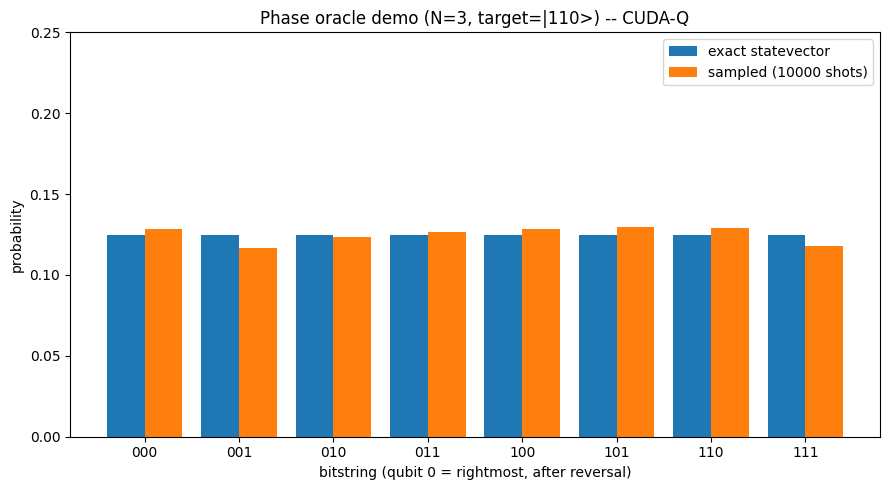

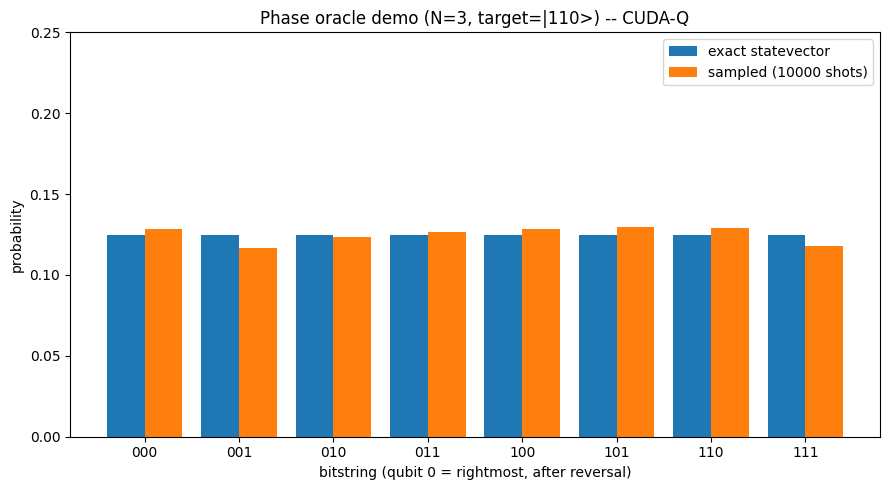

In [9]:
# Histogram: matplotlib bar chart, same style/axis ranges as the Qiskit notebook, saved to file
bitstrings_sorted = sorted(CUDAQ_PROBS_EXACT.keys())
exact_vals = [CUDAQ_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [CUDAQ_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=0)
ax.set_xlabel("bitstring (qubit 0 = rightmost, after reversal)")
ax.set_ylabel("probability")
ax.set_title(f"Phase oracle demo (N={N_QUBITS}, target=|{format(TARGET_INT, f'0{N_QUBITS}b')}>) -- CUDA-Q")
ax.set_ylim(0, 0.25)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_cudaq_histogram.png", dpi=150, bbox_inches="tight")
fig


In [10]:
# Resource counts (derived from the Python-side gate list, kept in sync with the kernel by construction --
# CUDA-Q does not expose a circuit.depth()/count_ops() introspection API equivalent to Qiskit's)
from collections import Counter
gate_type_counts = Counter(g[0] for g in gatelist)
print("Gate counts:", dict(gate_type_counts))
print("Total gate count:", len(gatelist))


Gate counts: {'H': 5, 'X': 2, 'MCX': 1}
Total gate count: 8


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character of every bitstring.
  `cudaq.get_state()`'s NumPy array already matches this (no reversal applied);
  `cudaq.sample()`'s bitstring keys are the opposite, so reversal **is** applied there.
- **Global phase convention:** the reversed exact statevector was multiplied by
  `exp(-i*phase)` where `phase` is the angle of the first amplitude (ascending bitstring
  order) with magnitude `> 1e-9`, so that amplitude is real and positive -- identical rule
  to the Qiskit notebook.
- **Basis ordering for all matrices:** ascending binary order `|000> ... |111>`.
- **Why the histogram looks flat:** same reason as the Qiskit notebook -- a phase oracle is
  a diagonal `±1` matrix, so it cannot change any measurement probability, only signs; the
  effect is verified directly in the statevector sign flip (Cell 7).


In [11]:
# Final result: exact-statevector-derived probability dictionary (reversed to qiskit convention)
CUDAQ_RESULT = {b: CUDAQ_PROBS_EXACT[b] for b in sorted(CUDAQ_PROBS_EXACT)}
print("CUDAQ_RESULT =")
for b, p in CUDAQ_RESULT.items():
    print(f"  '{b}': {p:.6f}")


CUDAQ_RESULT =
  '000': 0.125000
  '001': 0.125000
  '010': 0.125000
  '011': 0.125000
  '100': 0.125000
  '101': 0.125000
  '110': 0.125000
  '111': 0.125000


In [12]:
# Diff-check block (run AFTER also running the Qiskit notebook and pasting its QISKIT_RESULT below)
HAND_COMPUTED_EXPECTED = {format(i, f'0{N_QUBITS}b'): 1/(2**N_QUBITS) for i in range(2**N_QUBITS)}
max_delta_vs_hand = max(abs(CUDAQ_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in CUDAQ_RESULT)
print("Max delta between CUDAQ_RESULT and hand-computed expected (uniform 1/8):", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# QISKIT_RESULT = { ... }  # <- paste the dict printed at the end of the Qiskit notebook here
# max_delta = max(abs(CUDAQ_RESULT[b] - QISKIT_RESULT[b]) for b in CUDAQ_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q phase-oracle results disagree beyond tolerance!"


Max delta between CUDAQ_RESULT and hand-computed expected (uniform 1/8): 9.71445146547012e-17
